In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/ieee-fraud-detection/sample_submission.csv
/kaggle/input/competitions/ieee-fraud-detection/test_identity.csv
/kaggle/input/competitions/ieee-fraud-detection/train_identity.csv
/kaggle/input/competitions/ieee-fraud-detection/test_transaction.csv
/kaggle/input/competitions/ieee-fraud-detection/train_transaction.csv


In [3]:
import pandas as pd, numpy as np

p = "/kaggle/input/competitions/ieee-fraud-detection/"
tr = pd.read_csv(p + "train_transaction.csv")
idn = pd.read_csv(p + "train_identity.csv")
df = tr.merge(idn, on="TransactionID", how="left")

print(df.shape)
print("Fraud rate:", df.isFraud.mean())

(590540, 434)
Fraud rate: 0.03499000914417313


In [4]:
print(df.isFraud.value_counts())
print(df.isFraud.value_counts(normalize=True).round(4))

isFraud
0    569877
1     20663
Name: count, dtype: int64
isFraud
0    0.965
1    0.035
Name: proportion, dtype: float64


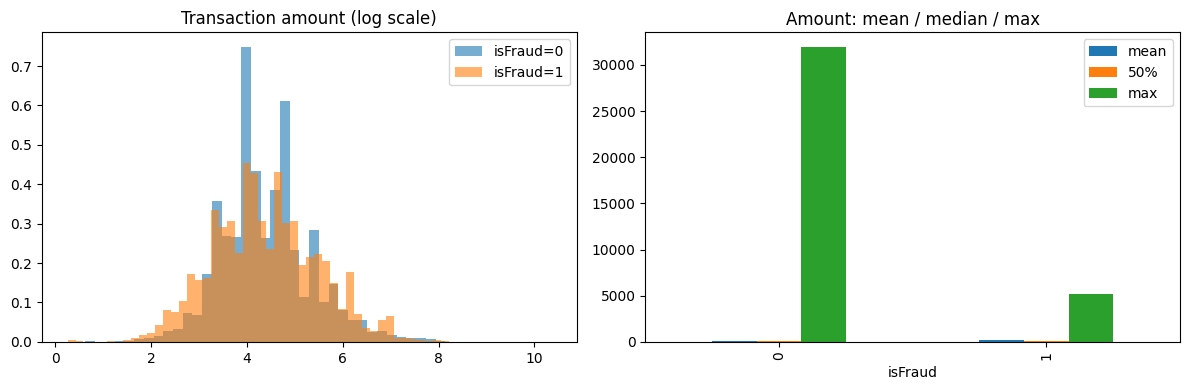

In [5]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for label, grp in df.groupby("isFraud"):
    ax[0].hist(np.log1p(grp.TransactionAmt), bins=50, alpha=0.6,
               density=True, label=f"isFraud={label}")
ax[0].set_title("Transaction amount (log scale)")
ax[0].legend()

df.groupby("isFraud").TransactionAmt.describe()[["mean", "50%", "max"]].plot.bar(ax=ax[1])
ax[1].set_title("Amount: mean / median / max")
plt.tight_layout()
plt.show()

In [6]:
missing = df.isna().mean().sort_values(ascending=False)
print(missing.head(15))
print("\nColumns with >50% missing:", (missing > 0.5).sum(), "of", df.shape[1])

id_24    0.991962
id_25    0.991310
id_07    0.991271
id_08    0.991271
id_21    0.991264
id_26    0.991257
id_27    0.991247
id_23    0.991247
id_22    0.991247
dist2    0.936284
D7       0.934099
id_18    0.923607
D13      0.895093
D14      0.894695
D12      0.890410
dtype: float64

Columns with >50% missing: 214 of 434


In [7]:
for col in ["ProductCD", "DeviceType", "card4", "card6"]:
    print(df.groupby(col, dropna=False).isFraud.agg(["mean", "count"]).round(4), "\n")
    

             mean   count
ProductCD                
C          0.1169   68519
H          0.0477   33024
R          0.0378   37699
S          0.0590   11628
W          0.0204  439670 

              mean   count
DeviceType                
desktop     0.0652   85165
mobile      0.1017   55645
NaN         0.0210  449730 

                    mean   count
card4                           
american express  0.0287    8328
discover          0.0773    6651
mastercard        0.0343  189217
visa              0.0348  384767
NaN               0.0260    1577 

                   mean   count
card6                          
charge card      0.0000      15
credit           0.0668  148986
debit            0.0243  439938
debit or credit  0.0000      30
NaN              0.0248    1571 



In [8]:
df = df.sort_values("TransactionDT").reset_index(drop=True)

# proxy user (the dataset has no user ID)
df["uid"] = df["card1"].astype(str) + "_" + df["addr1"].astype(str)
g = df.groupby("uid")

df["txn_count_so_far"] = g.cumcount()                      # velocity
df["secs_since_last"] = g["TransactionDT"].diff()          # time gap
prev_sum = g["TransactionAmt"].cumsum() - df["TransactionAmt"]
df["amt_user_avg"] = prev_sum / df["txn_count_so_far"].replace(0, np.nan)
df["amt_ratio"] = df["TransactionAmt"] / df["amt_user_avg"]

prev_dev = g["DeviceInfo"].shift()
df["device_changed"] = (prev_dev.notna() & df["DeviceInfo"].notna()
                        & (prev_dev != df["DeviceInfo"])).astype(int)
df["has_identity"] = df["DeviceType"].notna().astype(int)
print("features added")

features added


In [12]:
import xgboost as xgb
from sklearn.metrics import average_precision_score, roc_auc_score

for c in df.select_dtypes("object").columns.drop("uid"):
    df[c] = df[c].astype("category")

cut = df["TransactionDT"].quantile(0.8)
train, valid = df[df.TransactionDT <= cut], df[df.TransactionDT > cut]
feats = [c for c in df.columns if c not in ["isFraud", "TransactionID", "TransactionDT", "uid"]]

ratio = (1 - train.isFraud.mean()) / train.isFraud.mean()
model = xgb.XGBClassifier(
    n_estimators=400, max_depth=6, learning_rate=0.05,
    subsample=0.8, colsample_bytree=0.8,
    scale_pos_weight=ratio, tree_method="hist",
    enable_categorical=True, eval_metric="aucpr", n_jobs=-1,
)
model.fit(train[feats], train.isFraud,
          eval_set=[(valid[feats], valid.isFraud)], verbose=50)

p = model.predict_proba(valid[feats])[:, 1]
print("Valid fraud rate:", round(valid.isFraud.mean(), 4))
print("PR-AUC :", round(average_precision_score(valid.isFraud, p), 4))
print("ROC-AUC:", round(roc_auc_score(valid.isFraud, p), 4))

[0]	validation_0-aucpr:0.28938
[50]	validation_0-aucpr:0.40998
[100]	validation_0-aucpr:0.43923
[150]	validation_0-aucpr:0.44710
[200]	validation_0-aucpr:0.45716
[250]	validation_0-aucpr:0.46891
[300]	validation_0-aucpr:0.47469
[350]	validation_0-aucpr:0.47963
[399]	validation_0-aucpr:0.48541
Valid fraud rate: 0.0344
PR-AUC : 0.4855
ROC-AUC: 0.8888


In [13]:
import mlflow
mlflow.set_tracking_uri("sqlite:////kaggle/working/mlflow.db")
mlflow.set_experiment("fraud-detection")

with mlflow.start_run(run_name="xgb_baseline"):
    mlflow.log_params({"n_estimators": 400, "max_depth": 6, "learning_rate": 0.05,
                       "scale_pos_weight": round(ratio, 2), "n_features": len(feats)})
    mlflow.log_metrics({"pr_auc": 0.4855, "roc_auc": 0.8888})

runs = mlflow.search_runs(experiment_names=["fraud-detection"])
print(runs[["tags.mlflow.runName", "metrics.pr_auc", "metrics.roc_auc"]])

2026/10/21 09:25:40 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/21 09:25:41 INFO mlflow.store.db.utils: Updating database tables
2026/10/21 09:25:44 INFO mlflow.tracking.fluent: Experiment with name 'fraud-detection' does not exist. Creating a new experiment.


  tags.mlflow.runName  metrics.pr_auc  metrics.roc_auc
0        xgb_baseline          0.4855           0.8888


In [15]:
# --- new features ---
df["hour"] = (df.TransactionDT // 3600) % 24
df["dow"] = (df.TransactionDT // 86400) % 7
df["email_match"] = (df.P_emaildomain.astype(str) == df.R_emaildomain.astype(str)).astype(int)

cut = df.TransactionDT.quantile(0.8)
for c in ["card1", "card2", "addr1", "P_emaildomain", "DeviceInfo"]:
    counts = df.loc[df.TransactionDT <= cut, c].astype(object).value_counts()
    df[c + "_freq"] = df[c].astype(object).map(counts).astype("float32")

# --- re-split and train with early stopping ---
train, valid = df[df.TransactionDT <= cut], df[df.TransactionDT > cut]
feats2 = [c for c in df.columns if c not in ["isFraud", "TransactionID", "TransactionDT", "uid"]]

model2 = xgb.XGBClassifier(
    n_estimators=800, max_depth=6, learning_rate=0.05,
    subsample=0.8, colsample_bytree=0.8,
    scale_pos_weight=ratio, tree_method="hist",
    enable_categorical=True, eval_metric="aucpr", n_jobs=-1,
    early_stopping_rounds=100,
)
model2.fit(train[feats2], train.isFraud,
           eval_set=[(valid[feats2], valid.isFraud)], verbose=100)

p2 = model2.predict_proba(valid[feats2])[:, 1]
pr2 = average_precision_score(valid.isFraud, p2)
roc2 = roc_auc_score(valid.isFraud, p2)
print("Best iteration:", model2.best_iteration)
print("PR-AUC :", round(pr2, 4), "(baseline 0.4855)")
print("ROC-AUC:", round(roc2, 4), "(baseline 0.8888)")

with mlflow.start_run(run_name="xgb_v2_features_earlystop"):
    mlflow.log_params({"max_depth": 6, "learning_rate": 0.05,
                       "best_iteration": model2.best_iteration, "n_features": len(feats2)})
    mlflow.log_metrics({"pr_auc": pr2, "roc_auc": roc2})

[0]	validation_0-aucpr:0.28872
[100]	validation_0-aucpr:0.43728
[200]	validation_0-aucpr:0.45479
[300]	validation_0-aucpr:0.47166
[400]	validation_0-aucpr:0.48473
[500]	validation_0-aucpr:0.49085
[600]	validation_0-aucpr:0.49582
[700]	validation_0-aucpr:0.50281
[799]	validation_0-aucpr:0.50720
Best iteration: 799
PR-AUC : 0.5073 (baseline 0.4855)
ROC-AUC: 0.8908 (baseline 0.8888)


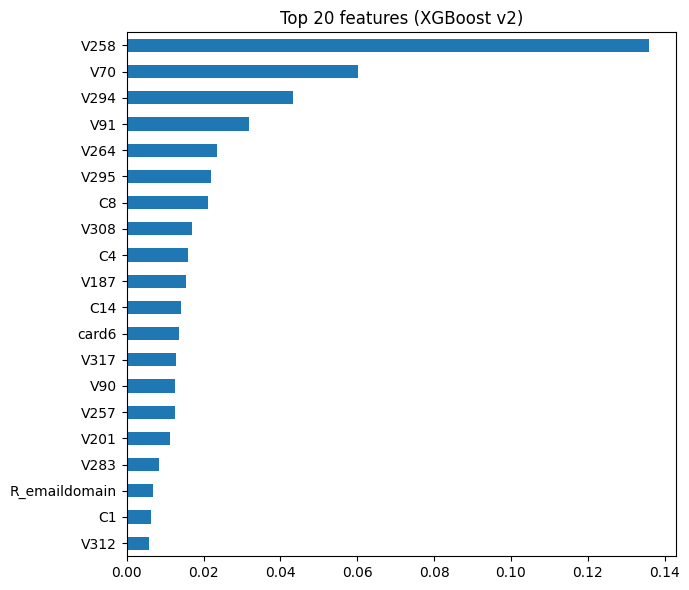

         tags.mlflow.runName  metrics.pr_auc  metrics.roc_auc
0  xgb_v2_features_earlystop        0.507253         0.890756
1               xgb_baseline        0.485500         0.888800


In [16]:
import json
import matplotlib.pyplot as plt

# 1) Feature importance chart
imp = pd.Series(model2.feature_importances_, index=feats2).sort_values().tail(20)
imp.plot.barh(figsize=(7, 6), title="Top 20 features (XGBoost v2)")
plt.tight_layout()
plt.savefig("/kaggle/working/feature_importance.png", dpi=150)
plt.show()

# 2) Save model and metadata for the API
model2.save_model("/kaggle/working/xgb_v2.json")
meta = {
    "features": feats2,
    "categories": {c: [str(x) for x in df[c].cat.categories]
                   for c in df[feats2].select_dtypes("category").columns},
    "best_iteration": int(model2.best_iteration),
    "pr_auc": float(pr2), "roc_auc": float(roc2),
}
json.dump(meta, open("/kaggle/working/model_meta.json", "w"))

# 3) Export the MLflow run table
runs = mlflow.search_runs(experiment_names=["fraud-detection"])
runs.to_csv("/kaggle/working/experiment_runs.csv", index=False)
print(runs[["tags.mlflow.runName", "metrics.pr_auc", "metrics.roc_auc"]])

In [17]:
mine = ["txn_count_so_far", "secs_since_last", "amt_user_avg", "amt_ratio",
        "device_changed", "has_identity", "hour", "dow", "email_match",
        "card1_freq", "card2_freq", "addr1_freq", "P_emaildomain_freq", "DeviceInfo_freq"]
s = pd.Series(model2.feature_importances_, index=feats2)
rank = s.rank(ascending=False).astype(int)
out = pd.DataFrame({"importance": s[mine].round(4), "rank": rank[mine]})
print(f"Rank out of {len(feats2)} features")
print(out.sort_values("importance", ascending=False))

Rank out of 445 features
                    importance  rank
email_match             0.0040    32
card2_freq              0.0023    84
card1_freq              0.0022    87
addr1_freq              0.0020    99
txn_count_so_far        0.0016   134
amt_user_avg            0.0014   151
DeviceInfo_freq         0.0014   163
P_emaildomain_freq      0.0013   179
secs_since_last         0.0013   168
hour                    0.0012   186
amt_ratio               0.0010   211
dow                     0.0008   247
device_changed          0.0001   414
has_identity            0.0000   432
